In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.outliers_influence import variance_inflation_factor, OLSInfluence

# Part 1)

In [2]:
peng = pd.read_csv("penguins.csv").dropna(
    subset=["flipper_length_mm", "body_mass_g", "bill_length_mm", "bill_depth_mm"]
).reset_index(drop=True)

print(f"n = {len(peng)}")

n = 342


### Question 1)

In [3]:
m1 = smf.ols("body_mass_g ~ flipper_length_mm", data=peng).fit()
m2 = smf.ols("body_mass_g ~ flipper_length_mm + bill_depth_mm", data=peng).fit()
m3 = smf.ols("body_mass_g ~ flipper_length_mm + bill_depth_mm + bill_length_mm", data=peng).fit()

sm.stats.anova_lm(m1, m2, m3)

,df_resid,ssr,df_diff,ss_diff,F,Pr(>F)
0,340.0,5.285480e+07,0.0,NaN,NaN,NaN
1,339.0,5.240575e+07,1.0,449043.646743,2.901411,0.089419
2,338.0,5.231136e+07,1.0,94393.101155,0.609903,0.435371


In [4]:
preds = ["flipper_length_mm", "bill_depth_mm", "bill_length_mm"]

def vif_table(df, cols):
    X = sm.add_constant(df[cols])
    return pd.DataFrame({
        "variable": cols,
        "VIF": [variance_inflation_factor(X.values, X.columns.get_loc(c)) for c in cols],
    }).round(2)

vif_table(peng, preds)

,variable,VIF
0,flipper_length_mm,2.67
1,bill_depth_mm,1.61
2,bill_length_mm,1.87


The difference is that we now also have the nested F-test, and it shows that bill_length and bill_depth don't earn their place using an alpha of 5%. This points to using flipper_length alone as the only predictor variable, which changes my answer from last week. VIFs are low across the board, so collinearity is not the reason the other variables don't earn their place. They just don't add enough predictive power to justify adding them.

### Question 2)

##### Part A)

In [5]:
bike = pd.read_csv("bike-sharing-daily.csv", parse_dates=["dteday"])
bike[["temp", "hum", "windspeed", "cnt"]].corr()

,temp,hum,windspeed,cnt
temp,1.000000,0.126963,-0.157944,0.627494
hum,0.126963,1.000000,-0.248489,-0.100659
windspeed,-0.157944,-0.248489,1.000000,-0.234545
cnt,0.627494,-0.100659,-0.234545,1.000000


<Axes: >

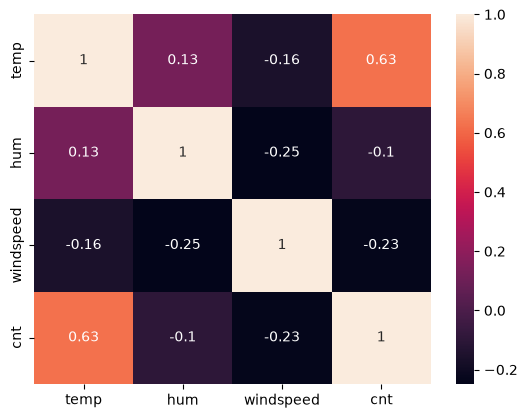

In [6]:
sns.heatmap(bike[["temp", "hum", "windspeed", "cnt"]].corr(), annot=True)

##### Part B)

In [7]:
model = smf.ols("cnt ~ temp + hum + windspeed", data=bike).fit()
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:                    cnt   R-squared:                       0.461
Model:                            OLS   Adj. R-squared:                  0.459
Method:                 Least Squares   F-statistic:                     207.2
Date:                Sun, 20 Sep 2026   Prob (F-statistic):           4.26e-97
Time:                        18:16:55   Log-Likelihood:                -6343.9
No. Observations:                 731   AIC:                         1.270e+04
Df Residuals:                     727   BIC:                         1.271e+04
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept   4084.3634    337.862     12.089      0.0

In [8]:
vif_table(bike, ["temp", "hum", "windspeed"])

,variable,VIF
0,temp,1.03
1,hum,1.07
2,windspeed,1.08


Temp is positive, so as it goes up there are more rentals, which makes sense since biking in the winter is not as enjoyable. Hum has a negative relationship, which also makes sense since the higher the humidity the more likely it is raining and people usually avoid biking in the rain. Finally windspeed is also negative and makes sense, high winds can make biking difficult and very high winds are indicative of a storm which people would not want to bike in.

##### Part C)

In [9]:
b1 = smf.ols("cnt ~ temp", data=bike).fit()
b2 = smf.ols("cnt ~ temp + hum", data=bike).fit()
b3 = smf.ols("cnt ~ temp + hum + windspeed", data=bike).fit()

sm.stats.anova_lm(b1, b2, b3)

,df_resid,ssr,df_diff,ss_diff,F,Pr(>F)
0,729.0,1.660847e+09,0.0,NaN,NaN,NaN
1,728.0,1.570304e+09,1.0,9.054330e+07,44.569779,4.869005e-11
2,727.0,1.476897e+09,1.0,9.340630e+07,45.979085,2.475445e-11


##### Part D)

I would choose the model cnt ~ temp + hum + windspeed. Both new variables have p-values less than 5%, so they both earn their place as predictors in the model.

# Part 2)

In [10]:
peng2 = peng.dropna(subset=["sex"]).reset_index(drop=True)

print(f"n = {len(peng2)}")

n = 333


### Question 1)

In [11]:
m342 = smf.ols("body_mass_g ~ flipper_length_mm + bill_length_mm + bill_depth_mm", data=peng).fit()
m333 = smf.ols("body_mass_g ~ flipper_length_mm + bill_length_mm + bill_depth_mm", data=peng2).fit()

pd.DataFrame({"n=342": m342.params, "n=333": m333.params}).round(2)

,n=342,n=333
Intercept,-6424.76,-6445.48
flipper_length_mm,50.27,50.76
bill_length_mm,4.16,3.29
bill_depth_mm,20.05,17.84


In [12]:
print(m333.summary())

                            OLS Regression Results                            
Dep. Variable:            body_mass_g   R-squared:                       0.764
Model:                            OLS   Adj. R-squared:                  0.762
Method:                 Least Squares   F-statistic:                     354.9
Date:                Sun, 20 Sep 2026   Prob (F-statistic):          9.26e-103
Time:                        18:16:56   Log-Likelihood:                -2459.8
No. Observations:                 333   AIC:                             4928.
Df Residuals:                     329   BIC:                             4943.
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
Intercept         -6445.4760    566.13

Removing the 9 penguins without sex data changes very little about the model, and predictors keep their same significance status.

### Question 2)

In [13]:
flip = smf.ols("body_mass_g ~ flipper_length_mm", data=peng2).fit()
add  = smf.ols("body_mass_g ~ flipper_length_mm + C(sex)", data=peng2).fit()
inter = smf.ols("body_mass_g ~ flipper_length_mm * C(sex)", data=peng2).fit()

sm.stats.anova_lm(flip, add, inter)

,df_resid,ssr,df_diff,ss_diff,F,Pr(>F)
0,331.0,5.121196e+07,0.0,NaN,NaN,NaN
1,330.0,4.179537e+07,1.0,9.416589e+06,74.126700,3.050629e-16
2,329.0,4.179409e+07,1.0,1.286001e+03,0.010123,9.199177e-01


In [14]:
print(add.summary().tables[1])

                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
Intercept         -5410.3002    285.798    -18.931      0.000   -5972.515   -4848.085
C(sex)[T.male]      347.8503     40.342      8.623      0.000     268.491     427.209
flipper_length_mm    46.9822      1.441     32.598      0.000      44.147      49.817


##### Part A)

The nested F-test shows sex earns its place as a predictive variable, but the interaction variable does not.

##### Part B)

Going from female to male adds about 350 grams of mass at the same flipper length.

##### Part C)

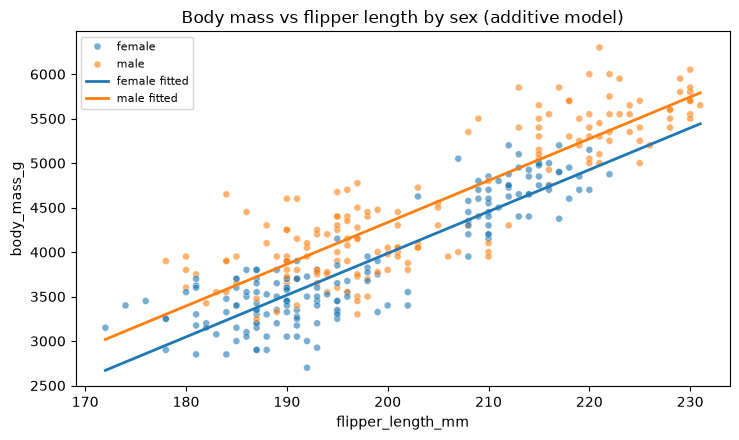

In [15]:
sexes = sorted(peng2.sex.unique())
palette = dict(zip(sexes, sns.color_palette(n_colors=len(sexes))))

fig, ax = plt.subplots(figsize=(7.5, 4.5))
sns.scatterplot(data=peng2, x="flipper_length_mm", y="body_mass_g",
                hue="sex", hue_order=sexes, palette=palette, alpha=0.6, s=25, ax=ax)
grid = np.linspace(peng2.flipper_length_mm.min(), peng2.flipper_length_mm.max(), 50)
for sx in sexes:
    pred = add.predict(pd.DataFrame({"flipper_length_mm": grid, "sex": sx}))
    ax.plot(grid, pred, lw=2, color=palette[sx], label=f"{sx} fitted")
ax.set_title("Body mass vs flipper length by sex (additive model)")
ax.legend(fontsize=8)
plt.tight_layout()

The scatter plot with fitted lines supports this, as the slope for the male and female populations is very similar and it is just the intercept that is different. So the male fitted line looks just like the female fitted line raised higher.

### Question 3)

In [16]:
add3 = smf.ols("body_mass_g ~ C(sex) + C(species)", data=peng2).fit()
int3 = smf.ols("body_mass_g ~ C(sex) * C(species)", data=peng2).fit()

sm.stats.anova_lm(add3, int3)

,df_resid,ssr,df_diff,ss_diff,F,Pr(>F)
0,329.0,3.297919e+07,0.0,NaN,NaN,NaN
1,327.0,3.130263e+07,2.0,1.676557e+06,8.756997,0.000197


In [17]:
print(int3.summary().tables[1])

                                             coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------------------------
Intercept                               3368.8356     36.212     93.030      0.000    3297.597    3440.074
C(sex)[T.male]                           674.6575     51.212     13.174      0.000     573.911     775.404
C(species)[T.Chinstrap]                  158.3703     64.240      2.465      0.014      31.994     284.747
C(species)[T.Gentoo]                    1310.9058     54.422     24.088      0.000    1203.844    1417.968
C(sex)[T.male]:C(species)[T.Chinstrap]  -262.8928     90.849     -2.894      0.004    -441.616     -84.170
C(sex)[T.male]:C(species)[T.Gentoo]      130.4372     76.436      1.706      0.089     -19.930     280.805


##### Part A)

The interaction model is the best since its p-value in the nested F-test is less than 5%.

##### Part B)

A female Adelie is our reference and with an intercept of about 3370 that is the average body weight for one. Changing to the male population adds about 675g to the average body weight. Changing the species to Chinstrap adds about 158 grams while changing it to Gentoo adds about 1311 grams. Switching to male Chinstrap the male increase is reduced by about 263 grams, and switching to male Gentoo the male increase is increased by about 130g, although that is not statistically significant.

##### Part C)

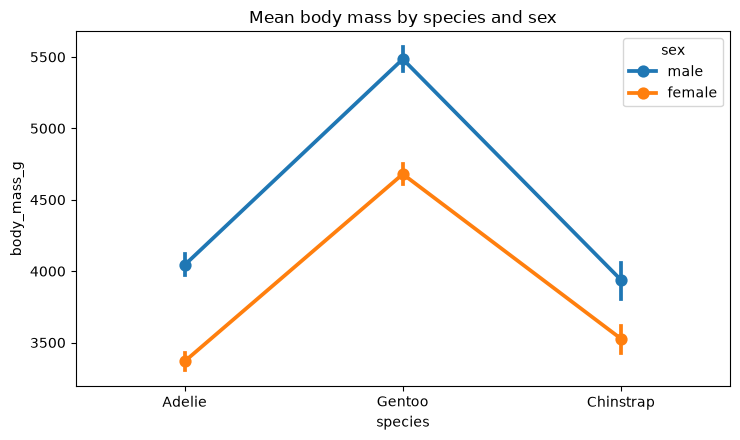

In [18]:
plt.figure(figsize=(7.5, 4.5))
sns.pointplot(data=peng2, x="species", y="body_mass_g", hue="sex")
plt.title("Mean body mass by species and sex")
plt.tight_layout()

Plotting the mean body weight by sex and species shows how the two variables affect the average weight for their populations. The male-female gap is visibly different across species, smallest for Chinstrap at about 412 grams and largest for Gentoo at about 805 grams, which is the interaction we found in the model.

### Question 4)

##### Part A)

In [19]:
cas_add = smf.ols("casual ~ temp + C(workingday) + hum + windspeed", data=bike).fit()
cas_int = smf.ols("casual ~ temp * C(workingday) + hum + windspeed", data=bike).fit()

sm.stats.anova_lm(cas_add, cas_int)

,df_resid,ssr,df_diff,ss_diff,F,Pr(>F)
0,726.0,1.276423e+08,0.0,NaN,NaN,NaN
1,725.0,1.103186e+08,1.0,1.732378e+07,113.849712,8.681452e-25


In [20]:
print(cas_int.summary().tables[1])

                              coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------------
Intercept                 492.5703    108.430      4.543      0.000     279.696     705.445
C(workingday)[T.1]         68.4230     87.703      0.780      0.436    -103.759     240.605
temp                     3354.7267    138.592     24.206      0.000    3082.638    3626.815
temp:C(workingday)[T.1] -1792.4490    167.989    -10.670      0.000   -2122.252   -1462.646
hum                      -840.4351    105.137     -7.994      0.000   -1046.844    -634.026
windspeed               -1102.3863    194.061     -5.681      0.000   -1483.375    -721.398


The interaction model is better since in the nested F-test it has a p-value less than 5%.

##### Part B)

In [21]:
reg_add = smf.ols("registered ~ temp + C(workingday) + hum + windspeed", data=bike).fit()
reg_int = smf.ols("registered ~ temp * C(workingday) + hum + windspeed", data=bike).fit()

sm.stats.anova_lm(reg_add, reg_int)

,df_resid,ssr,df_diff,ss_diff,F,Pr(>F)
0,726.0,1.020706e+09,0.0,NaN,NaN,NaN
1,725.0,1.016851e+09,1.0,3.855347e+06,2.748806,0.09776


In [22]:
print(reg_int.summary().tables[1])

                              coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------------
Intercept                3215.1761    329.195      9.767      0.000    2568.886    3861.466
C(workingday)[T.1]        519.6323    266.268      1.952      0.051      -3.116    1042.381
temp                     3891.6346    420.767      9.249      0.000    3065.568    4717.701
temp:C(workingday)[T.1]   845.5850    510.018      1.658      0.098    -155.703    1846.873
hum                     -2281.0250    319.198     -7.146      0.000   -2907.687   -1654.363
windspeed               -3676.6403    589.172     -6.240      0.000   -4833.328   -2519.953


The additive model is better here since in the nested F-test the interaction model has a p-value higher than 5%.

##### Part C)

Parts a and b show that temperature's impact does differ by day type for casual riders, and it does not for registered riders.

##### Part D)

We are making predictive models for two separate populations, and it would not make sense to add one as a predictor of the other since every rental is either casual or registered. The two groups behave differently, and modeling the total count would average those behaviors together and hide the interaction casual riders show, since registered riders have no interaction and dilute it in the aggregate.

# Part 3)

### Question 1)

##### Part A)

In [23]:
peng_full = smf.ols("body_mass_g ~ flipper_length_mm + bill_length_mm + bill_depth_mm", data=peng).fit()
infl = OLSInfluence(peng_full)

n, p = int(peng_full.nobs), peng_full.df_model
print(f"n = {n}, p = {p:.0f}")

diag = pd.DataFrame({
    "mass":        peng.body_mass_g,
    "fitted":      peng_full.fittedvalues,
    "student_resid": infl.resid_studentized_external,
    "leverage":    infl.hat_matrix_diag,
    "cooks_d":     infl.cooks_distance[0],
    "sex_missing": peng.sex.isna(),
})
diag.head(10)

n = 342, p = 3


,mass,fitted,student_resid,leverage,cooks_d,sex_missing
0,3750.0,3211.617868,1.376420,0.008831,0.004209,False
1,3800.0,3438.564312,0.921907,0.007306,0.001564,False
2,3250.0,3906.346483,-1.676699,0.004599,0.003230,False
3,3450.0,3816.889879,-0.938715,0.013330,0.002977,False
4,3650.0,3702.967340,-0.135413,0.014287,0.000067,False
5,3625.0,3192.740924,1.104655,0.009992,0.003077,False
6,4675.0,3933.847733,1.902148,0.011451,0.010398,False
7,3475.0,3782.009706,-0.786136,0.015675,0.002463,True
8,4250.0,3706.184442,1.391234,0.010026,0.004887,True
9,3300.0,3425.474357,-0.319884,0.008505,0.000220,True


##### Part B)

In [24]:
lev_cut, cook_cut = 2 * (p + 1) / n, 4 / n
print(f"leverage cutoff = {lev_cut:.4f}   Cook's D cutoff = {cook_cut:.4f}")

print(f"outliers   (|studentized resid| > 3): {(diag.student_resid.abs() > 3).sum()}")
print(f"high leverage (h > 2(p+1)/n):        {(diag.leverage > lev_cut).sum()}")
print(f"influential   (Cook's D > 4/n):      {(diag.cooks_d > cook_cut).sum()}")

leverage cutoff = 0.0234   Cook's D cutoff = 0.0117
outliers   (|studentized resid| > 3): 1
high leverage (h > 2(p+1)/n):        10
influential   (Cook's D > 4/n):      13


In [25]:
diag[diag.sex_missing][["mass", "fitted", "student_resid", "leverage", "cooks_d"]]

,mass,fitted,student_resid,leverage,cooks_d
7,3475.0,3782.009706,-0.786136,0.015675,0.002463
8,4250.0,3706.184442,1.391234,0.010026,0.004887
9,3300.0,3425.474357,-0.319884,0.008505,0.000220
10,3700.0,3127.868934,1.465755,0.012216,0.006620
46,2975.0,3108.430419,-0.340460,0.010170,0.000299
177,4100.0,4905.296510,-2.067466,0.010211,0.010919
217,4650.0,4813.838115,-0.417769,0.008677,0.000383
255,4725.0,4906.924841,-0.464586,0.011531,0.000631
267,4875.0,4983.635078,-0.277006,0.008949,0.000174


The cutoffs are leverage > 0.0234, Cook's D > 0.0117, and |studentized residual| > 3. These flag 1 outlier, 10 high-leverage points, and 13 influential points in the full model. None of the 9 sex-missing penguins exceed any of the cutoffs.

##### Part C)

None of the 9 removed penguins hit any of the cutoffs, so removing them from the dataset will not drastically change the model. There is little concern in removing them, and it would not change my earlier answer.

##### Part D)

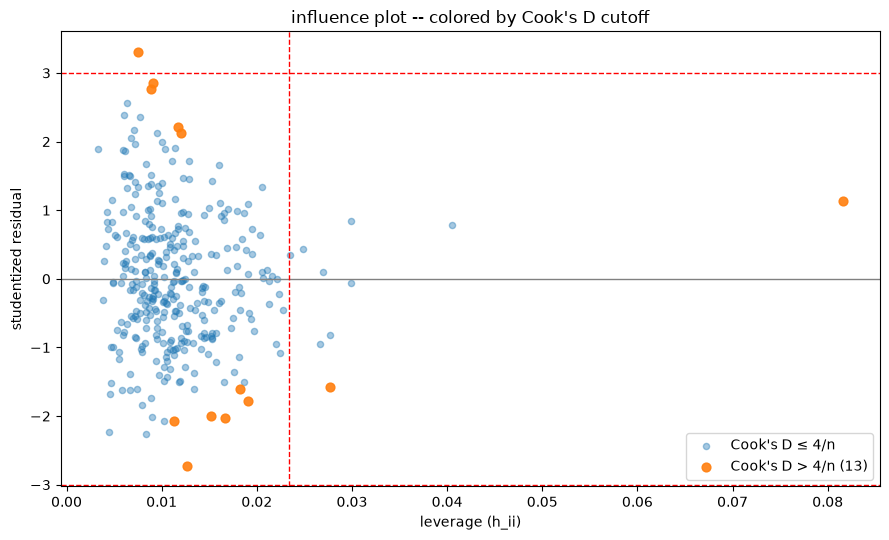

In [26]:
infl_flag = diag.cooks_d > cook_cut

fig, ax = plt.subplots(figsize=(9, 5.5))
ax.scatter(diag.leverage[~infl_flag], diag.student_resid[~infl_flag], s=20, alpha=0.4,
           color="tab:blue", label="Cook's D ≤ 4/n")
ax.scatter(diag.leverage[infl_flag], diag.student_resid[infl_flag], s=40, alpha=0.9,
           color="tab:orange", label=f"Cook's D > 4/n ({infl_flag.sum()})")
ax.axhline(0, color="gray", lw=1)
for y in (-3, 3):
    ax.axhline(y, color="red", ls="--", lw=1)
ax.axvline(lev_cut, color="red", ls="--", lw=1)
ax.set(xlabel="leverage (h_ii)", ylabel="studentized residual",
       title="influence plot -- colored by Cook's D cutoff")
ax.legend()
plt.tight_layout()

Most points cluster around low leverage and a studentized residual near 0, and there is one point with very high leverage. All the points over the cutoff for Cook's D either have a higher |studentized residual|, a high leverage, or both.

### Question 2)

In [27]:
model_bike = smf.ols("cnt ~ temp + hum + windspeed + C(season) + C(weathersit)", data=bike).fit()
infl = OLSInfluence(model_bike)

n, p = int(model_bike.nobs), model_bike.df_model
print(f"n = {n}, p = {p:.0f}")

diag = pd.DataFrame({
    "date":          bike.dteday,
    "cnt":           bike.cnt,
    "fitted":        model_bike.fittedvalues,
    "student_resid": infl.resid_studentized_external,
    "leverage":      infl.hat_matrix_diag,
    "cooks_d":       infl.cooks_distance[0],
})
diag[(diag.date == "2012-10-29") | (diag.date == "2012-03-17")]

n = 731, p = 8


,date,cnt,fitted,student_resid,leverage,cooks_d
441,2012-03-17,7836,3740.305424,3.203567,0.016568,0.018968
667,2012-10-29,22,1941.204734,-1.522793,0.054691,0.014880


In [28]:
m_full  = smf.ols("cnt ~ temp + hum + windspeed + C(season) + C(weathersit)", data=bike).fit()
m_no29  = smf.ols("cnt ~ temp + hum + windspeed + C(season) + C(weathersit)",
                  data=bike[bike.dteday != "2012-10-29"]).fit()
m_no317 = smf.ols("cnt ~ temp + hum + windspeed + C(season) + C(weathersit)",
                  data=bike[bike.dteday != "2012-03-17"]).fit()

pd.DataFrame({"full": m_full.params, "no 10-29": m_no29.params, "no 03-17": m_no317.params}).round(2)

,full,no 10-29,no 03-17
Intercept,3128.94,3099.87,3125.60
C(season)[T.2],926.97,924.05,980.28
C(season)[T.3],471.32,467.54,544.85
C(season)[T.4],1496.78,1505.25,1538.74
C(weathersit)[T.2],-218.77,-220.74,-237.06
C(weathersit)[T.3],-1902.85,-1815.60,-1916.20
temp,6205.41,6220.06,6085.88
hum,-2635.17,-2621.32,-2630.16
windspeed,-3330.79,-3258.90,-3237.75


Removing the day of Hurricane Sandy has little impact on the model, and since a hurricane itself is a clear outlier event that is very unlikely to occur again, I would recommend removing it. 2012-03-17 is a different story: its removal has a much larger impact on the model, and without a good reason to explain why that day was so unusual and why it shouldn't be expected to happen again, I would recommend keeping it. To a stakeholder I would report the two days and give the recommendation to exclude the Hurricane Sandy event but leave in 2012-03-17, given its large impact on the model and no outside explanation for it like a hurricane.

# Part 5)

Log transformations allow us to model non-linear relationships with a linear model, though the decision to use one is somewhat subjective. It is specifically useful when the data is skewed and has non-constant variance. Scaling allows features with different ranges to be modeled with comparable ranges, which prevents a model from overvaluing a feature with larger numbers. One thing to watch out for is to only scale on the training data, since scaling on the test data as well would leak info into training. Scikit-learn supports both standardization and normalization. Standardization centers data and scales it by its standard deviation so that every feature has unit variance and the same impact on the model, independent of the sizes of the numbers. Normalization is for scaling each sample itself, not the column as a whole, and is useful when comparing samples. We saw log transformation earlier in class when trying to model how a planet's distance from the sun is related to its orbit size. We saw that without the log transformation the model was a very poor fit and predicted negative distances from the sun for planets with shorter orbits. My biggest question would be what test could we use to make the decision to use a transformation less subjective.

# AI Acknowledgment 

I used an AI assistant to help write code for this lab. I checked the outputs myself against the data and the class materials to make sure the code worked correctly. I also used AI to help with spelling and grammar in my written answers. All questions were answered in my own words.